# 🌌 Sistema de Reconhecimento de EPBs usando 2DPCA — V3

## Equatorial Plasma Bubbles Detection System

### Versão simplificada

Hiperparâmetros fixos selecionados a partir da otimização exaustiva da V2,
onde **todas as 30 combinações testadas atingiram F1=1.0000**.
A configuração mais leve (menos árvores, menor profundidade) foi escolhida
para maximizar velocidade sem perda de performance.

---

### 🎯 Características do Sistema:

- ✅ **2DPCA** para extração de features preservando estrutura espacial
- ✅ **Ensemble** de 3 classificadores (SVM RBF + XGBoost + Random Forest)
- ✅ **SMOTE** para balanceamento de classes
- ✅ **Validação cruzada** estratificada
- ✅ **Interpretabilidade** via mapas de importância
- ✅ **Métricas clínicas** (Sensitivity, Specificity, PPV, NPV)

---

**Autor:** Alberto Ivo da Costa Vieira

In [1]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix)

from epb_detection_system import (
    load_epb_dataset, augment_epb_data,
    plot_comprehensive_analysis, explain_feature_importance,
    analyze_threshold_sensitivity, plot_calibration_analysis,
    evaluate_kfold_cv, benchmark_baselines,
    explain_shap_importance, setup_logging,
)
from epb_detection_system import EPBRecognitionSystem

setup_logging()

In [2]:
# ========== CONFIGURAÇÕES ==========
DATA_FOLDER = 'data/all-images'         # Pasta com todas as imagens
LABEL_FILE = 'data/epb_labels.csv'      # CSV com labels

TARGET_SIZE = (64, 64)           # Tamanho das imagens
AUGMENT_FACTOR = 3               # Fator de aumento para data augmentation
BALANCE_METHOD = 'smote'         # 'smote', 'undersample', ou 'combined'

# Hiperparâmetros fixos — escolhidos na V2 (todos os 30 candidatos
# atingiram F1=1.0; esta é a configuração mais leve/rápida).
N_COMPONENTS = 5                 # Componentes 2DPCA
ENSEMBLE_PARAMS = {
    'n_components': 5,
    'svm_C': 10.0,
    'svm_gamma': 'auto',
    'xgb_n_estimators': 100,     # menor = mais rápido
    'xgb_max_depth': 3,          # menor = mais rápido
    'xgb_learning_rate': 0.05,
    'rf_n_estimators': 100,      # menor = mais rápido (V2 usou 300)
    'rf_max_depth': 10,          # menor = mais rápido (V2 usou None)
    'meta_C': 0.1,
}

In [3]:
MODEL_VERSION = '3.0'

# Seed global para reprodutibilidade
np.random.seed(42)

print("="*70)
print("🌌 SISTEMA DE RECONHECIMENTO DE EPBs — V3 (simplificada)")
print("="*70)

# ========== ETAPA 1: CARREGAMENTO E PRÉ-PROCESSAMENTO ==========
print("\n" + "="*70)
print("ETAPA 1: CARREGAMENTO E PRÉ-PROCESSAMENTO")
print("="*70)

X, y, filenames = load_epb_dataset(
    data_folder=DATA_FOLDER,
    label_file=LABEL_FILE,
    target_size=TARGET_SIZE,
    apply_preprocessing=True
)

# Divisão estratificada
X_train, X_test, y_train, y_test, files_train, files_test = train_test_split(
    X, y, filenames, test_size=0.25, random_state=42, stratify=y
)

print(f"\n📦 Divisão estratificada:")
print(f"   • Treino: {len(X_train)} imagens (EPB: {int(y_train.sum())}, Sem EPB: {int(len(y_train) - y_train.sum())})")
print(f"   • Teste: {len(X_test)} imagens (EPB: {int(y_test.sum())}, Sem EPB: {int(len(y_test) - y_test.sum())})")

INFO: Carregando dataset de EPBs...
INFO: Labels carregados: 572 registros


🌌 SISTEMA DE RECONHECIMENTO DE EPBs — V3 (simplificada)

ETAPA 1: CARREGAMENTO E PRÉ-PROCESSAMENTO


INFO: 572 imagens carregadas com sucesso
INFO: Dimensão das imagens: 64x64
INFO: Distribuição das classes:
INFO:   EPBs detectados: 255 (44.6%)
INFO:   No EPB: 317 (55.4%)



📦 Divisão estratificada:
   • Treino: 429 imagens (EPB: 191, Sem EPB: 238)
   • Teste: 143 imagens (EPB: 64, Sem EPB: 79)


In [4]:
# ========== ETAPA 2: DATA AUGMENTATION ==========
if len(X_train) < 2000:
    print("="*70)
    print("ETAPA 2: DATA AUGMENTATION")
    print("="*70)

    X_train, y_train = augment_epb_data(X_train, y_train, augment_factor=AUGMENT_FACTOR)

INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 238 imgs (fator=x3)
INFO:   Classe 1: 191 imgs (fator=x5)


ETAPA 2: DATA AUGMENTATION


INFO: Dataset expandido: 429 → 1669 imagens (classe 0: 238→714, classe 1: 191→955)


In [5]:
# ========== ETAPA 3: TREINAMENTO DO SISTEMA ==========
print("="*70)
print("ETAPA 3: TREINAMENTO DO SISTEMA COMPLETO")
print("="*70)

system = EPBRecognitionSystem(
    n_components=N_COMPONENTS,
    balance_data=True,
    balance_method=BALANCE_METHOD,
    ensemble_params=ENSEMBLE_PARAMS,
)

system.fit(X_train, y_train)

INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 55.77%
INFO: Extraindo features...


ETAPA 3: TREINAMENTO DO SISTEMA COMPLETO


INFO: Shape das features: (1669, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Usando hiperparâmetros otimizados do ensemble:
INFO:   n_components: 5
INFO:   svm_C: 10.0
INFO:   svm_gamma: auto
INFO:   xgb_n_estimators: 100
INFO:   xgb_max_depth: 3
INFO:   xgb_learning_rate: 0.05
INFO:   rf_n_estimators: 100
INFO:   rf_max_depth: 10
INFO:   meta_C: 0.1
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 714 → 955
INFO: Classe 1: 955 → 955
INFO: Treinamento concluído!


In [6]:
# ========== ETAPA 4: AVALIAÇÃO NO CONJUNTO DE TESTE ==========
print("="*70)
print("ETAPA 4: AVALIAÇÃO NO CONJUNTO DE TESTE")
print("="*70)

y_pred = system.predict(X_test)
y_proba = system.predict_proba(X_test)

print("\n📊 MÉTRICAS DE PERFORMANCE:")
print("="*70)
print(classification_report(y_test, y_pred, target_names=['Sem EPB', 'EPB'], digits=4))

# Métricas específicas para EPBs
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
npv = tn / (tn + fn) if (tn + fn) > 0 else 0

print("\n📈 MÉTRICAS CLÍNICAS (IMPORTANTES PARA EPBs):")
print("="*70)
print(f"   • Sensitivity (Recall EPB):  {sensitivity*100:.2f}% ← Detecta EPBs reais")
print(f"   • Specificity:               {specificity*100:.2f}% ← Evita falsos alarmes")
print(f"   • PPV (Precision EPB):       {ppv*100:.2f}% ← Confiança quando detecta")
print(f"   • NPV:                       {npv*100:.2f}% ← Confiança quando não detecta")

print(f"\n   Interpretação:")
if sensitivity > 0.85:
    print(f"   ✓ Excelente detecção de EPBs (perde poucos eventos)")
elif sensitivity > 0.70:
    print(f"   ⚠️  Boa detecção, mas pode perder alguns EPBs")
else:
    print(f"   ❌ Detecção insuficiente - ajuste o modelo")

if specificity > 0.85:
    print(f"   ✓ Poucos falsos alarmes")
else:
    print(f"   ⚠️  Muitos falsos alarmes - ajuste threshold")

ETAPA 4: AVALIAÇÃO NO CONJUNTO DE TESTE

📊 MÉTRICAS DE PERFORMANCE:
              precision    recall  f1-score   support

     Sem EPB     0.9625    0.9747    0.9686        79
         EPB     0.9683    0.9531    0.9606        64

    accuracy                         0.9650       143
   macro avg     0.9654    0.9639    0.9646       143
weighted avg     0.9651    0.9650    0.9650       143


📈 MÉTRICAS CLÍNICAS (IMPORTANTES PARA EPBs):
   • Sensitivity (Recall EPB):  95.31% ← Detecta EPBs reais
   • Specificity:               97.47% ← Evita falsos alarmes
   • PPV (Precision EPB):       96.83% ← Confiança quando detecta
   • NPV:                       96.25% ← Confiança quando não detecta

   Interpretação:
   ✓ Excelente detecção de EPBs (perde poucos eventos)
   ✓ Poucos falsos alarmes


ETAPA 4b: ANÁLISE DE SENSIBILIDADE AO THRESHOLD


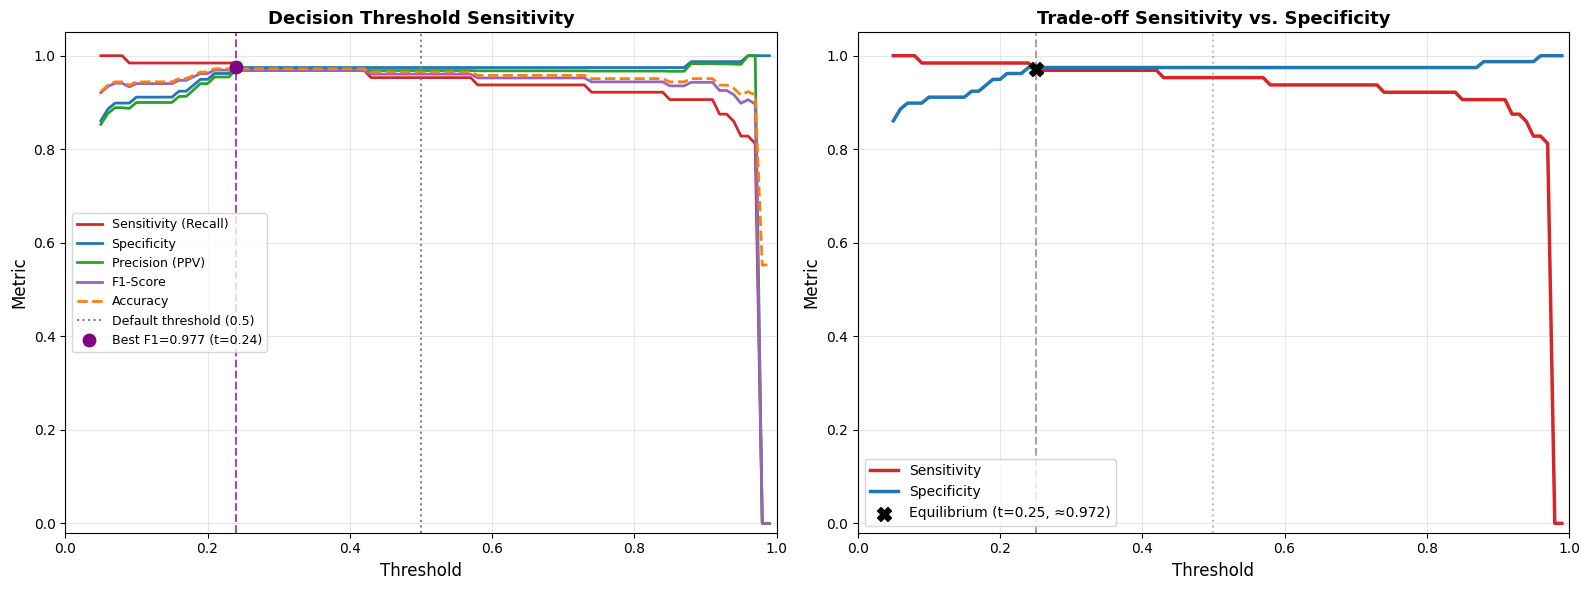


📊 ANÁLISE DE SENSIBILIDADE AO THRESHOLD

   Metric                   t=0.50      Best F1  Equilibrium
   --------------------------------------------------------
   Threshold                  0.50         0.24         0.25
   Sensitivity              0.9531       0.9844       0.9688
   Specificity              0.9747       0.9747       0.9747
   Precision                0.9683       0.9692       0.9688
   F1-Score                 0.9606       0.9767       0.9688
   Accuracy                 0.9650       0.9790       0.9720

   💡 Recomendação:
      O melhor F1 ocorre em t=0.24 (< 0.50) — o threshold padrão
      é conservador. Baixar o threshold aumenta a detecção de EPBs.



In [7]:
# ========== ETAPA 4b: ANÁLISE DE SENSIBILIDADE AO THRESHOLD ==========
print("="*70)
print("ETAPA 4b: ANÁLISE DE SENSIBILIDADE AO THRESHOLD")
print("="*70)

fig_threshold, df_thresholds = analyze_threshold_sensitivity(y_test, y_proba)

ETAPA 4c: ANÁLISE DE CALIBRAÇÃO DE PROBABILIDADES


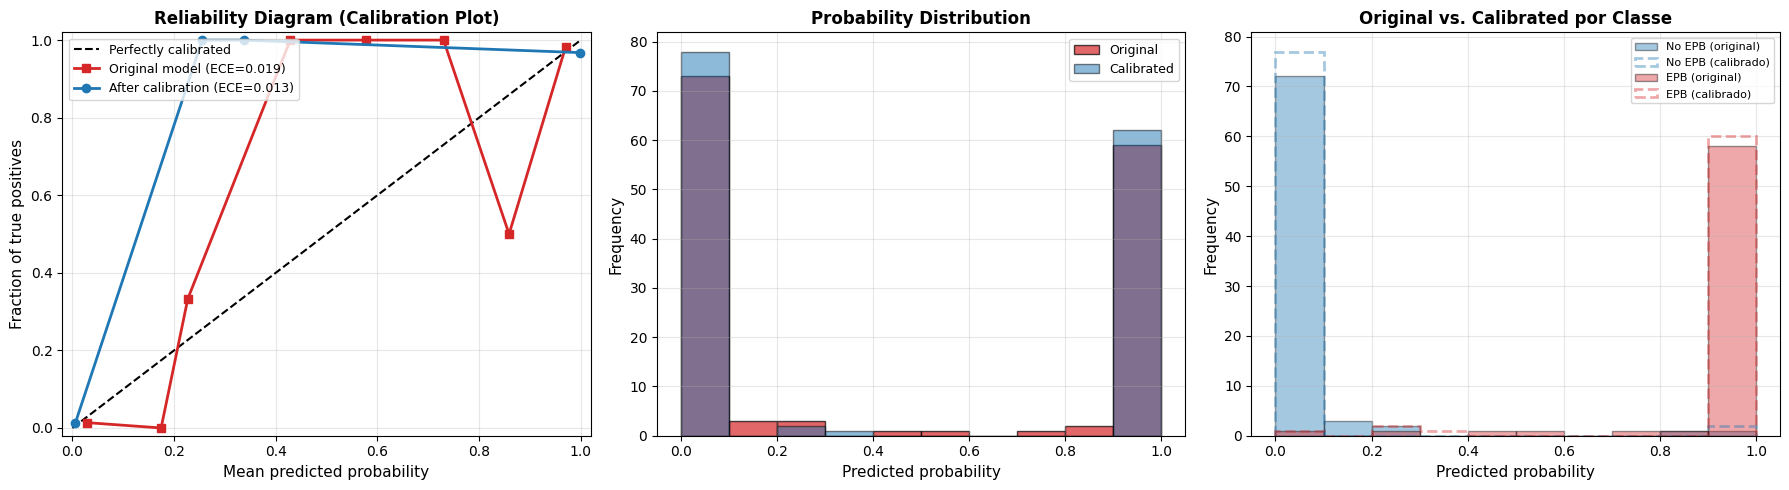


📊 ANÁLISE DE CALIBRAÇÃO DE PROBABILIDADES

   ECE original (Expected Calibration Error): 0.0186
   ✓ Probabilidades bem calibradas
   ECE após calibração isotónica:              0.0134
   ✓ Calibração melhorou o ECE em 0.0052

   💡 Interpretação do reliability diagram:
      Se os pontos ficam ACIMA da diagonal: modelo é subconfiante
        (diz 60%, mas na verdade 80% são positivos)
      Se os pontos ficam ABAIXO da diagonal: modelo é sobreconfiante
        (diz 80%, mas na verdade só 60% são positivos)



In [8]:
# ========== ETAPA 4c: ANÁLISE DE CALIBRAÇÃO DE PROBABILIDADES ==========
print("="*70)
print("ETAPA 4c: ANÁLISE DE CALIBRAÇÃO DE PROBABILIDADES")
print("="*70)

# Prepara features normalizadas para calibração comparativa
X_train_feat = system.scaler.transform(system.extract_features(X_train))
X_test_feat = system.scaler.transform(system.extract_features(X_test))

fig_cal, cal_stats = plot_calibration_analysis(
    y_true=y_test,
    y_proba=y_proba,
    system=system,
    X_train_features=X_train_feat,
    y_train=y_train,
    X_test_features=X_test_feat,
)

INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 253 imgs (fator=x3)
INFO:   Classe 1: 204 imgs (fator=x5)



📊 AVALIAÇÃO K-FOLD CROSS-VALIDATION (5 folds)
   Components: 5 | Balanceamento: smote
   Augmentation: Sim (fator=3)
   Total de amostras: 572 (255 EPB, 317 No EPB)



INFO: Dataset expandido: 457 → 1779 imagens (classe 0: 253→759, classe 1: 204→1020)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 55.88%
INFO: Extraindo features...
INFO: Shape das features: (1779, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 759 → 1020
INFO: Classe 1: 1020 → 1020
INFO: Treinamento concluído!
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 253 imgs (fator=x3)
INFO:   Classe 1: 204 imgs (fator=x5)


   Fold 1/5: Acc=0.9826 | Sens=1.0000 | Spec=0.9688 | F1=0.9808 | AUC=0.9991


INFO: Dataset expandido: 457 → 1779 imagens (classe 0: 253→759, classe 1: 204→1020)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 55.75%
INFO: Extraindo features...
INFO: Shape das features: (1779, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 759 → 1020
INFO: Classe 1: 1020 → 1020
INFO: Treinamento concluído!
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 254 imgs (fator=x3)
INFO:   Classe 1: 204 imgs (fator=x5)


   Fold 2/5: Acc=0.9739 | Sens=0.9412 | Spec=1.0000 | F1=0.9697 | AUC=0.9994


... (2 outputs left out)

INFO: Dataset expandido: 458 → 1782 imagens (classe 0: 254→762, classe 1: 204→1020)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 55.19%
INFO: Extraindo features...
INFO: Shape das features: (1782, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 762 → 1020
INFO: Classe 1: 1020 → 1020
INFO: Treinamento concluído!
INFO: Aplicando Data Augmentation estratificado (fator base=3)...
INFO:   Classe 0: 254 imgs (fator=x3)
INFO:   Classe 1: 204 imgs (fator=x5)


   Fold 4/5: Acc=0.9561 | Sens=0.9216 | Spec=0.9841 | F1=0.9495 | AUC=0.9956


INFO: Dataset expandido: 458 → 1782 imagens (classe 0: 254→762, classe 1: 204→1020)
INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 55.54%
INFO: Extraindo features...
INFO: Shape das features: (1782, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 762 → 1020
INFO: Classe 1: 1020 → 1020
INFO: Treinamento concluído!
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2484: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_melt, x='Metric', y='Value', ax=ax, palette='Set2')
/home/ivo/Documentos/Mestrado/dissertação/code/epb_detection_system.py:2489: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() o

   Fold 5/5: Acc=0.9561 | Sens=0.9216 | Spec=0.9841 | F1=0.9495 | AUC=0.9966

📈 RESULTADOS 5-FOLD CROSS-VALIDATION

   Metric                    Média      ± Std        Mín        Máx
   ------------------------------------------------------------
   Accuracy                 0.9685     0.0119     0.9561     0.9826
   Sensitivity              0.9569     0.0402     0.9216     1.0000
   Specificity              0.9779     0.0180     0.9524     1.0000
   Precision                0.9730     0.0208     0.9444     1.0000
   F1                       0.9642     0.0141     0.9495     0.9808
   Auc                      0.9976     0.0016     0.9956     0.9994

   💡 Para reportar na dissertação:
      F1-Score: 0.9642 ± 0.0141
      AUC:      0.9976 ± 0.0016
      Sens.:    0.9569 ± 0.0402


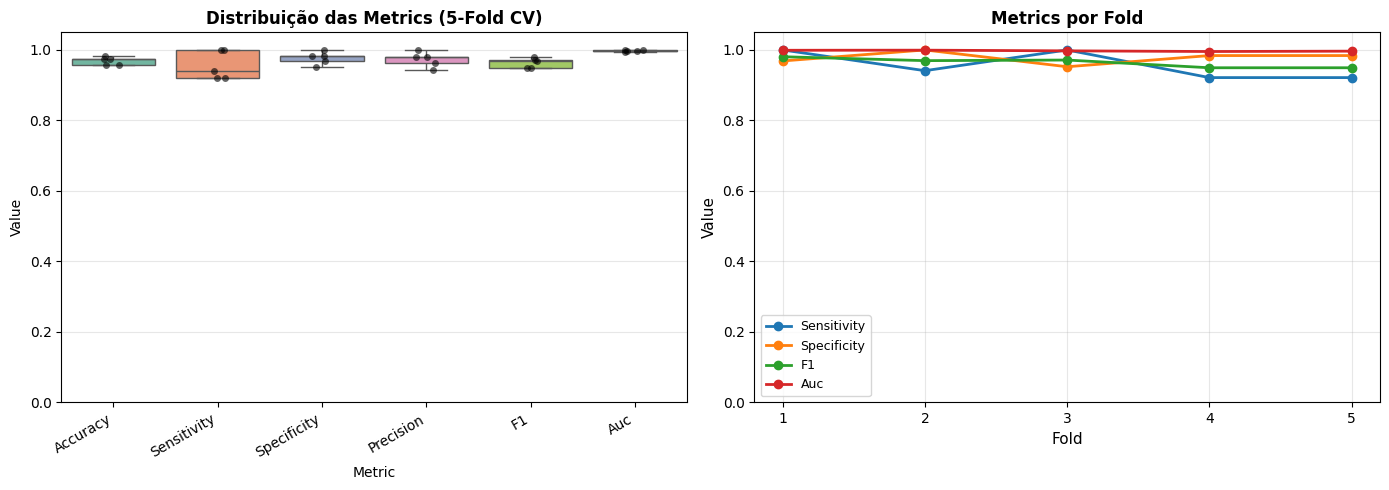

In [9]:
# ========== ETAPA 4d: AVALIAÇÃO K-FOLD CROSS-VALIDATION ==========
# Usa os dados ORIGINAIS (X, y) antes de augmentation/split
# para avaliar o pipeline completo com intervalos de confiança.
# Cada fold treina do zero: augmentation → 2DPCA → SMOTE → ensemble.

fig_kfold, df_kfold = evaluate_kfold_cv(
    X, y,
    n_components=N_COMPONENTS,
    n_folds=5,
    balance_method=BALANCE_METHOD,
    use_augmentation=True,
    augment_factor=AUGMENT_FACTOR,
)


📊 BENCHMARKING CONTRA BASELINES
   Train: 1669 | Test: 143 | Components: 5

   Flatten + LogReg       Acc=0.9720 | Sens=0.9688 | Spec=0.9747 | F1=0.9688 | AUC=0.9947
   PCA + LogReg           Acc=0.9650 | Sens=0.9688 | Spec=0.9620 | F1=0.9612 | AUC=0.9962
   PCA + SVM RBF          Acc=0.9510 | Sens=1.0000 | Spec=0.9114 | F1=0.9481 | AUC=0.9907
   Flatten + RF           Acc=0.9720 | Sens=1.0000 | Spec=0.9494 | F1=0.9697 | AUC=0.9989


INFO: Iniciando treinamento do sistema...
INFO: Treinando 2DPCA para extração de features...
INFO: Variância explicada: 55.77%
INFO: Extraindo features...
INFO: Shape das features: (1669, 320)
INFO: Normalizando features...
INFO: Criando classificador ensemble...
INFO: Montando pipeline com balanceamento (smote)...
INFO: Classe 0: 714 → 955
INFO: Classe 1: 955 → 955


   2DPCA + SVM RBF        Acc=0.9790 | Sens=0.9844 | Spec=0.9747 | F1=0.9767 | AUC=0.9972


INFO: Treinamento concluído!


   2DPCA + Ensemble ★     Acc=0.9720 | Sens=0.9688 | Spec=0.9747 | F1=0.9688 | AUC=0.9960

Modelo                        Acc     Sens     Spec     Prec       F1      AUC
------------------------------------------------------------------------
Flatten + LogReg           0.9720   0.9688   0.9747   0.9688   0.9688   0.9947
PCA + LogReg               0.9650   0.9688   0.9620   0.9538   0.9612   0.9962
PCA + SVM RBF              0.9510   1.0000   0.9114   0.9014   0.9481   0.9907
Flatten + RF               0.9720   1.0000   0.9494   0.9412   0.9697   0.9989
2DPCA + SVM RBF            0.9790   0.9844   0.9747   0.9692   0.9767   0.9972
2DPCA + Ensemble ★         0.9720   0.9688   0.9747   0.9688   0.9688   0.9960

   💡 Vantagem do 2DPCA+Ensemble sobre o melhor baseline:
      ΔF1 = -0.0079 (pior)
      ❌ O baseline é melhor — reveja a arquitetura.


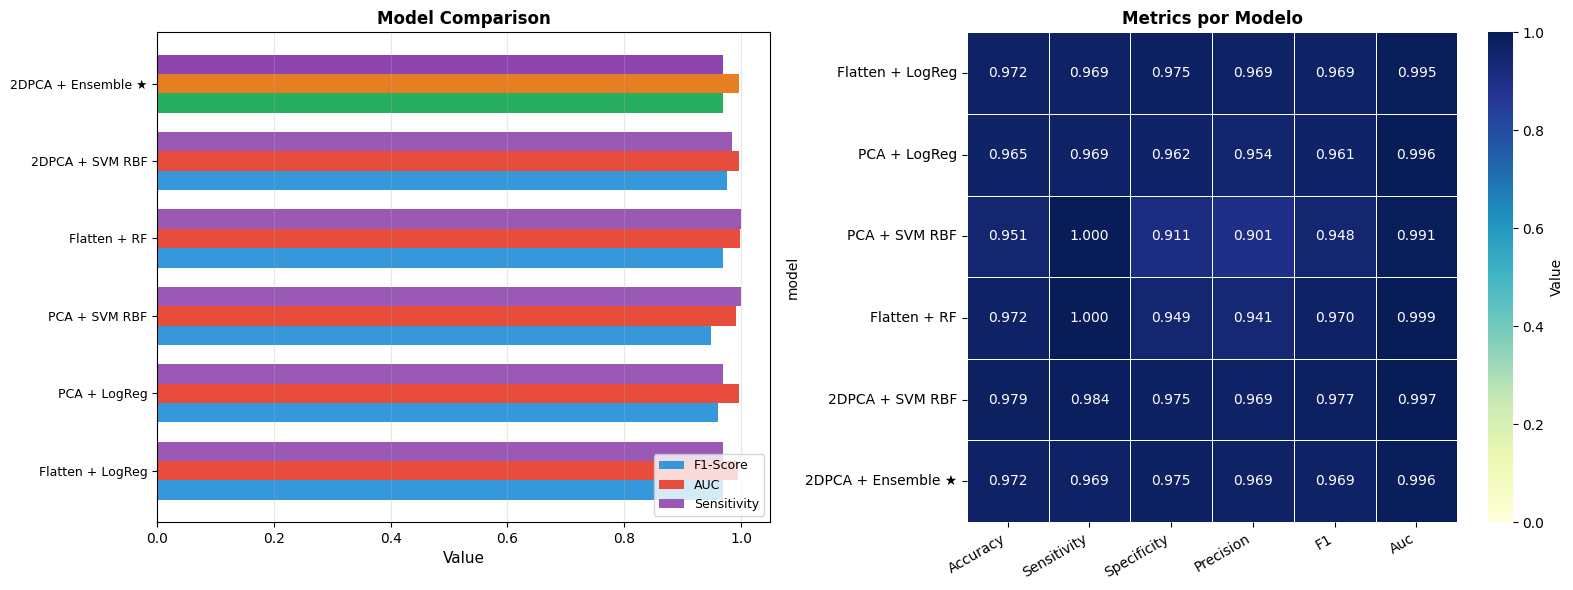

In [ ]:
# ========== ETAPA 4e: BENCHMARKING CONTRA BASELINES ==========
# Compara o sistema 2DPCA+Ensemble contra modelos mais simples.
# Justifica a complexidade da arquitetura escolhida.

fig_bench, df_bench = benchmark_baselines(
    X_train, y_train,
    X_test, y_test,
    n_components=N_COMPONENTS,
    balance_method=BALANCE_METHOD,
)

ETAPA 5: VISUALIZAÇÃO E ANÁLISE


/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127756 (\N{MILKY WAY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


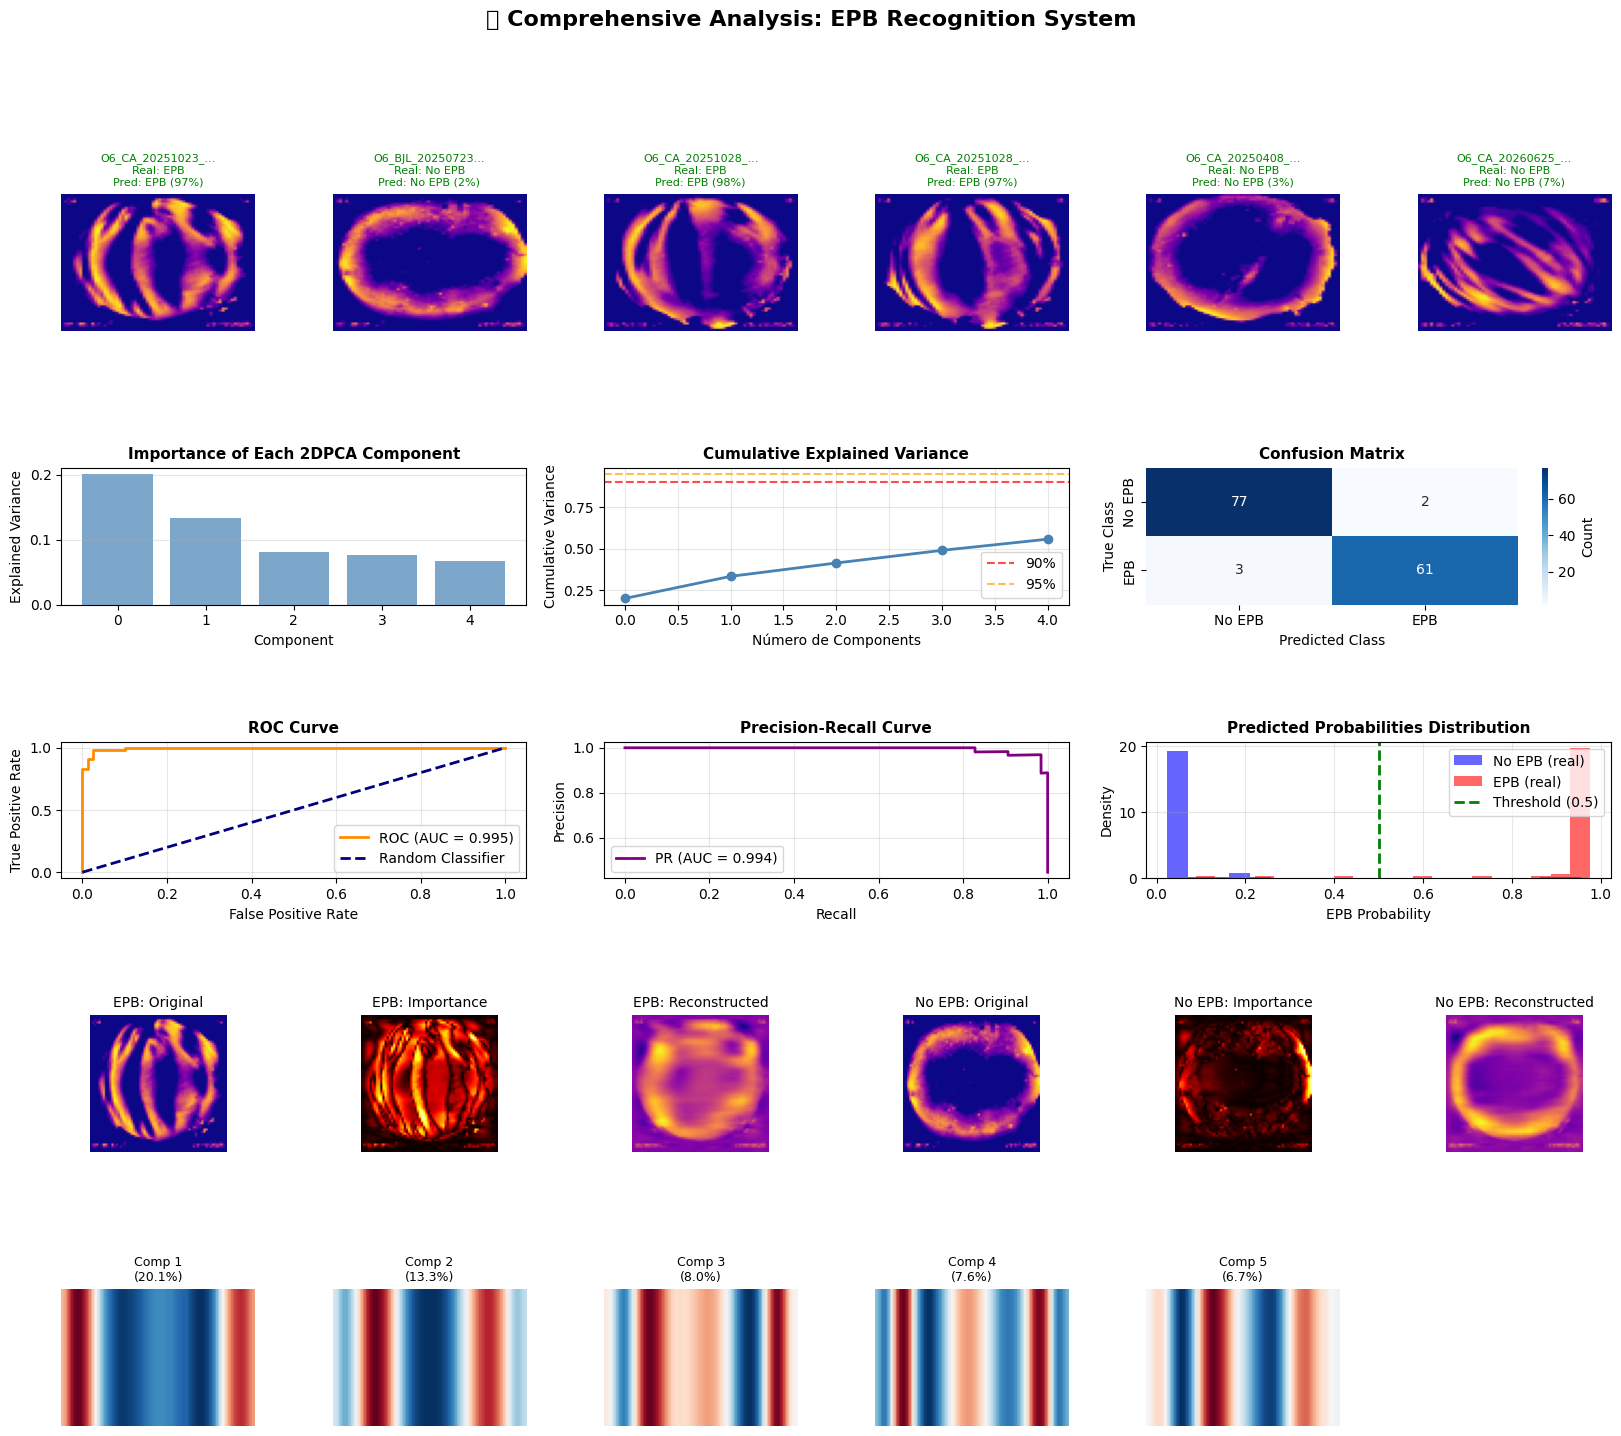

/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: Glyph 127756 (\N{MILKY WAY}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)


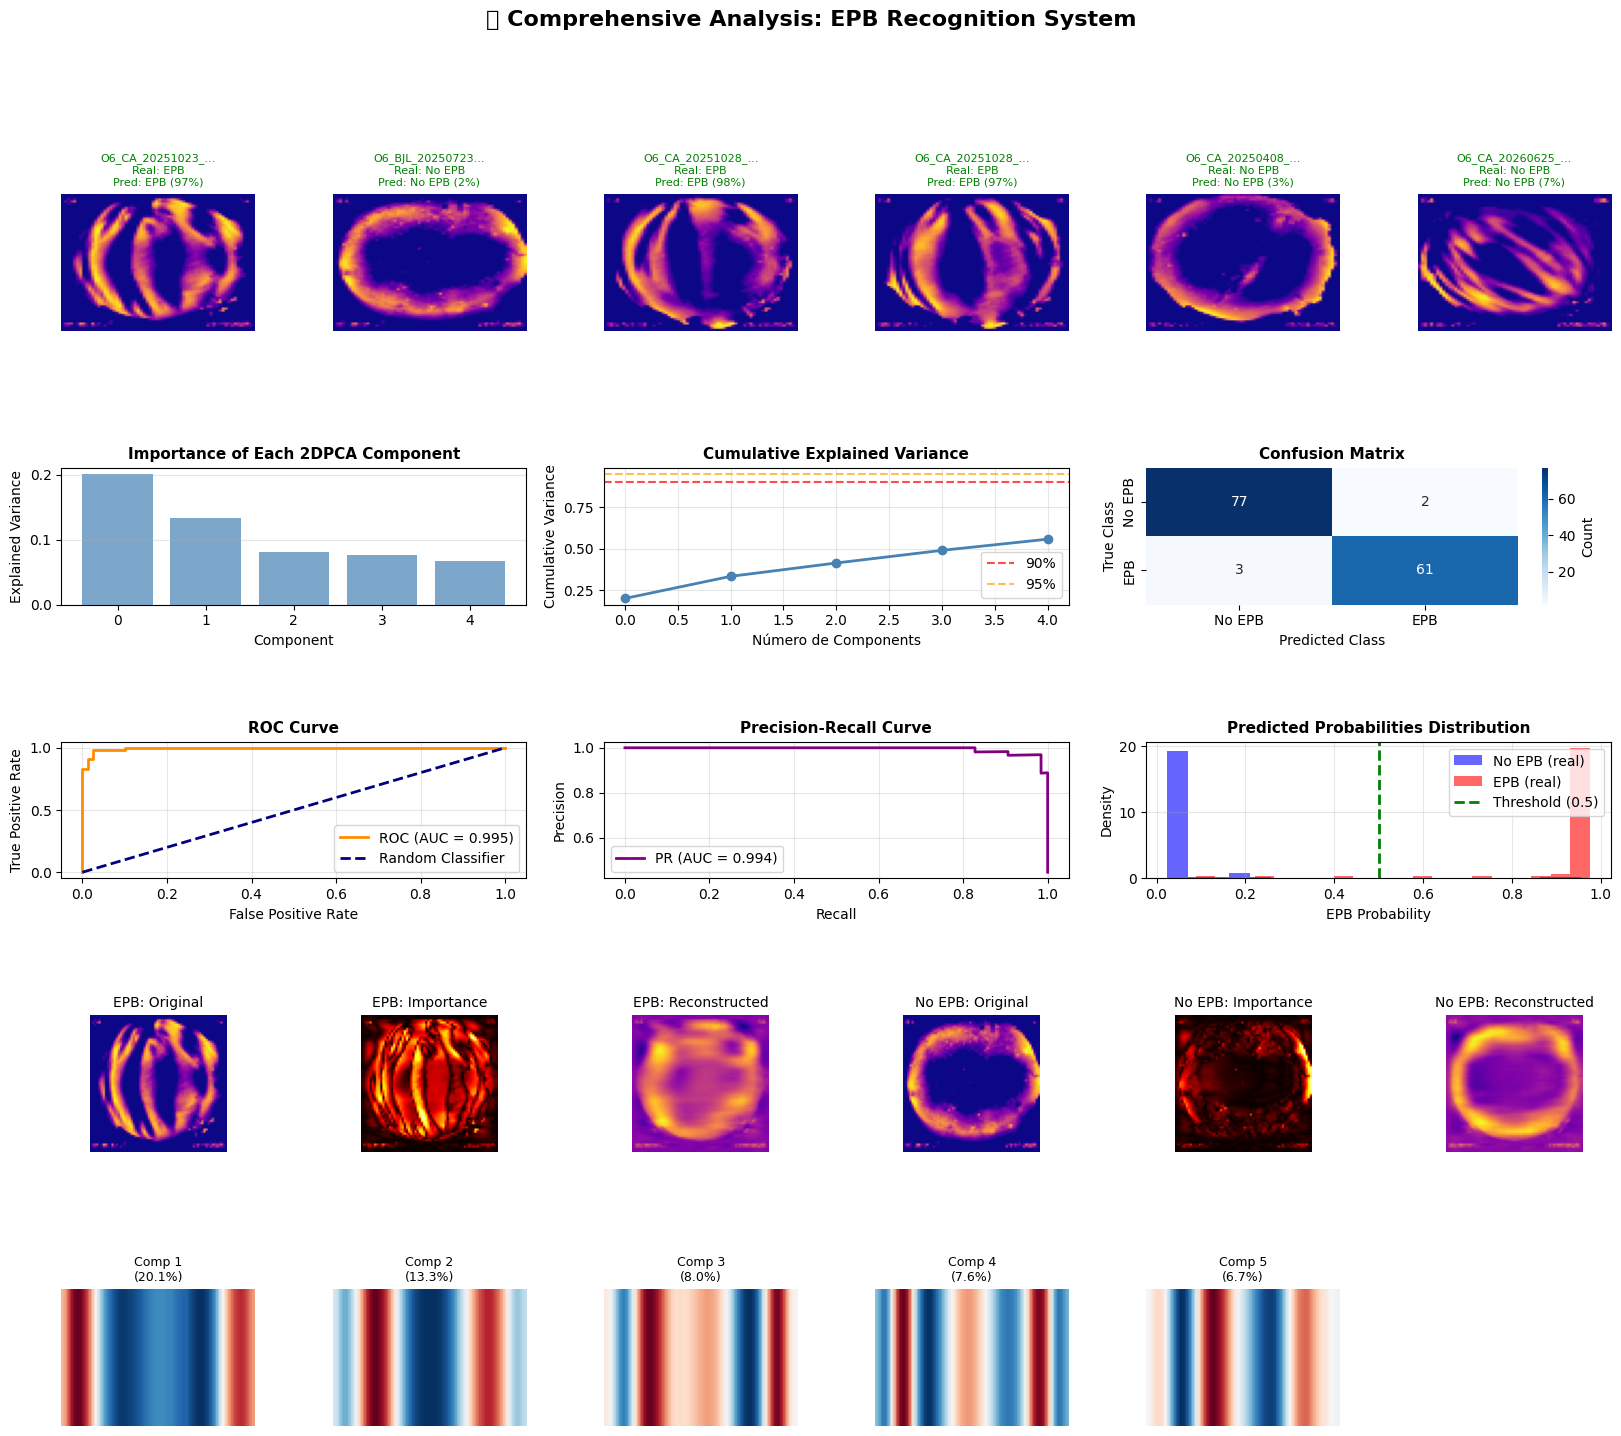

In [11]:
# ========== ETAPA 5: VISUALIZAÇÃO E ANÁLISE ==========
print("="*70)
print("ETAPA 5: VISUALIZAÇÃO E ANÁLISE")
print("="*70)

plot_comprehensive_analysis(system, X_train, X_test, y_train, y_test,
                                y_pred, y_proba, files_test)

ETAPA 6: INTERPRETAÇÃO DE FEATURES (EXEMPLOS)

🔍 FEATURE INTERPRETATION

📸 Imagem: O6_CA_20251023_014643.png
   • True class: EPB
   • Prediction: EPB
   • Probabilidade EPB: 97.37%
   • Confidence: Alta

📊 Most important regions (critical pixels):
   • Upper Left: 152 pixels (37.1%)
   • Lower Left: 147 pixels (35.9%)
   • Upper Right: 72 pixels (17.6%)
   • Lower Right: 39 pixels (9.5%)

💡 Interpretation:
   ✓ The model identified characteristic EPB patterns:
     - Vertical/irregular structures
     - Localized plasma depletions
     - Typical spatial distribution of bubbles


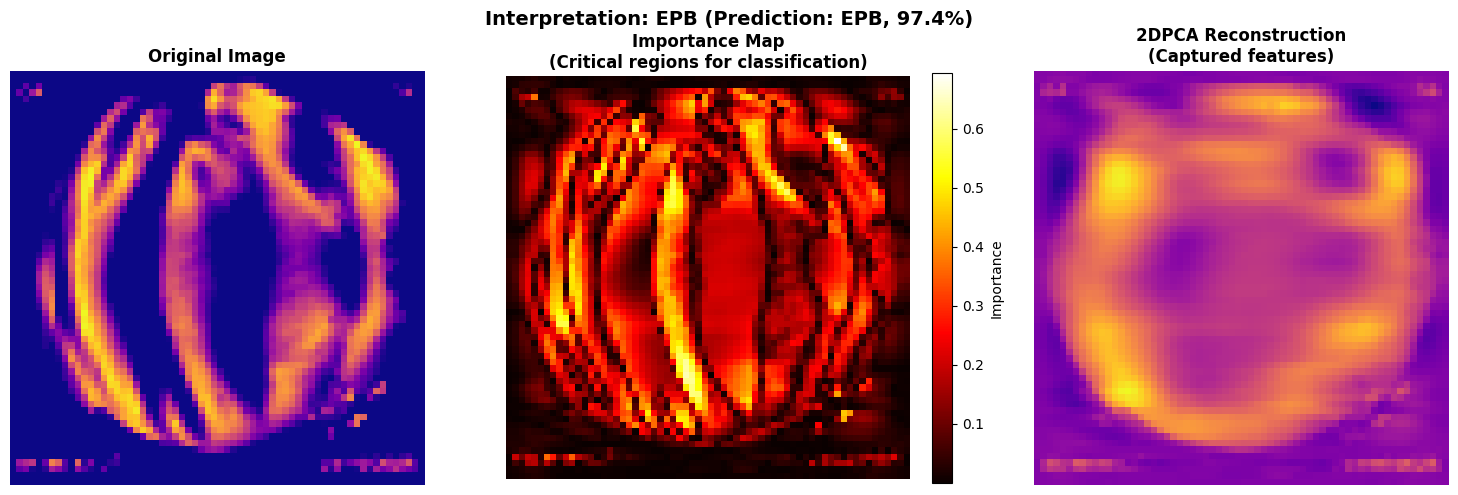


⚠️  ANÁLISE DE FALSO POSITIVO:

🔍 FEATURE INTERPRETATION

📸 Imagem: O6_CA_20260625_055650.png
   • True class: No EPB
   • Prediction: EPB
   • Probabilidade EPB: 87.38%
   • Confidence: Alta

📊 Most important regions (critical pixels):
   • Upper Left: 135 pixels (32.9%)
   • Lower Left: 117 pixels (28.5%)
   • Upper Right: 94 pixels (22.9%)
   • Lower Right: 64 pixels (15.6%)

💡 Interpretation:
   ✓ The model identified characteristic EPB patterns:
     - Vertical/irregular structures
     - Localized plasma depletions
     - Typical spatial distribution of bubbles


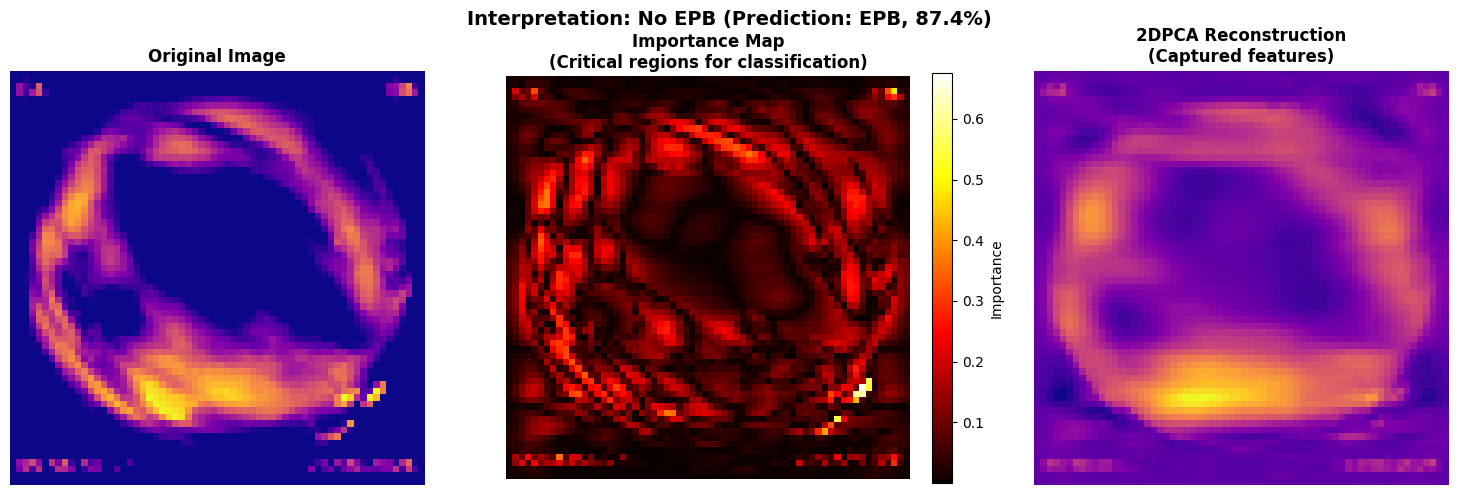


⚠️  ANÁLISE DE FALSO NEGATIVO:

🔍 FEATURE INTERPRETATION

📸 Imagem: O6_CA_20251219_021243.png
   • True class: EPB
   • Prediction: No EPB
   • Probabilidade EPB: 24.00%
   • Confidence: Média

📊 Most important regions (critical pixels):
   • Lower Left: 152 pixels (37.1%)
   • Lower Right: 95 pixels (23.2%)
   • Upper Left: 89 pixels (21.7%)
   • Upper Right: 74 pixels (18.0%)

💡 Interpretation:
   ✓ The model did NOT detect EPB patterns:
     - Uniform plasma distribution
     - Absence of irregular structures
     - Quiet ionosphere characteristics


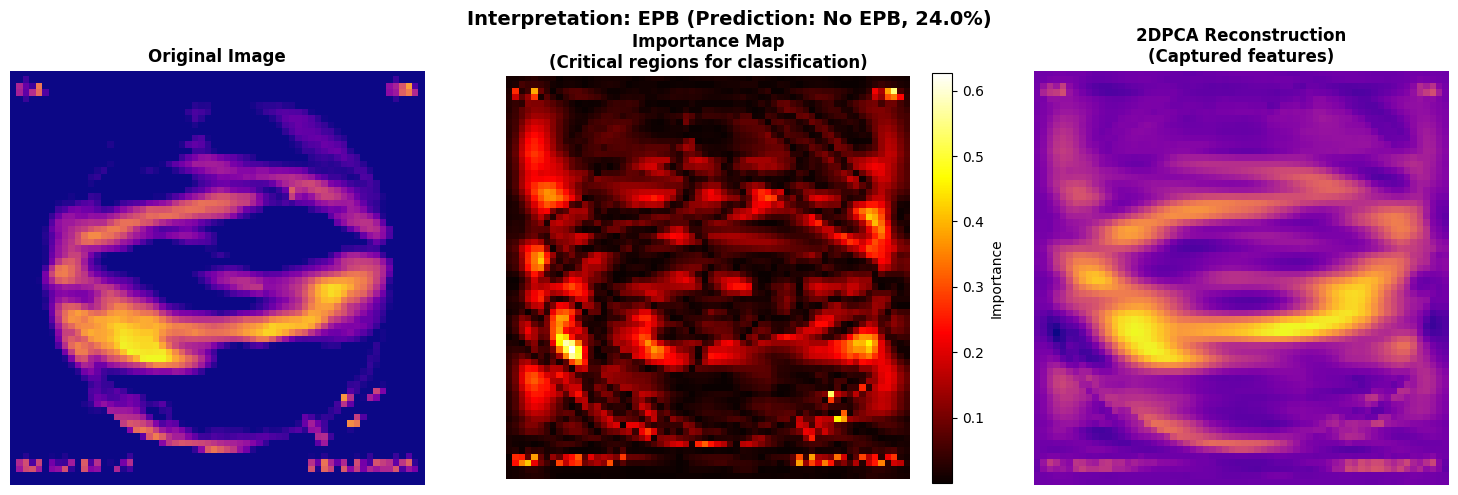

In [12]:
# ========== ETAPA 6: INTERPRETAÇÃO DE FEATURES (EXEMPLOS) ==========
print("="*70)
print("ETAPA 6: INTERPRETAÇÃO DE FEATURES (EXEMPLOS)")
print("="*70)

# Exemplo 1: EPB corretamente classificado
epb_correct_idx = np.where((y_test == 1) & (y_pred == 1))[0]
if len(epb_correct_idx) > 0:
    idx = epb_correct_idx[0]
    explain_feature_importance(system, X_test[idx], y_test[idx], files_test[idx])

# Exemplo 2: Falso positivo (se existir)
fp_idx = np.where((y_test == 0) & (y_pred == 1))[0]
if len(fp_idx) > 0:
    print("\n⚠️  ANÁLISE DE FALSO POSITIVO:")
    idx = fp_idx[0]
    explain_feature_importance(system, X_test[idx], y_test[idx], files_test[idx])

# Exemplo 3: Falso negativo (se existir)
fn_idx = np.where((y_test == 1) & (y_pred == 0))[0]
if len(fn_idx) > 0:
    print("\n⚠️  ANÁLISE DE FALSO NEGATIVO:")
    idx = fn_idx[0]
    explain_feature_importance(system, X_test[idx], y_test[idx], files_test[idx])

ETAPA 6b: ANÁLISE SHAP — IMPORTÂNCIA REAL PARA CLASSIFICAÇÃO


/home/ivo/miniconda3/envs/mestrado/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_CA_20251023_014643.png
   • True class: EPB
   • Prediction: EPB (97.4%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Lower Left: 37.3% (↑ EPB)
   • Lower Right: 33.0% (↓ No EPB)
   • Upper Right: 15.5% (↑ EPB)
   • Upper Left: 14.2% (↑ EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.427 (Spearman)
   → Correlação moderada: SHAP revela regiões adicionais

💡 Interpretation:
   As regiões vermelhas no mapa SHAP mostram onde o modelo
   encontra evidência de EPB (estruturas verticais, deplecções).


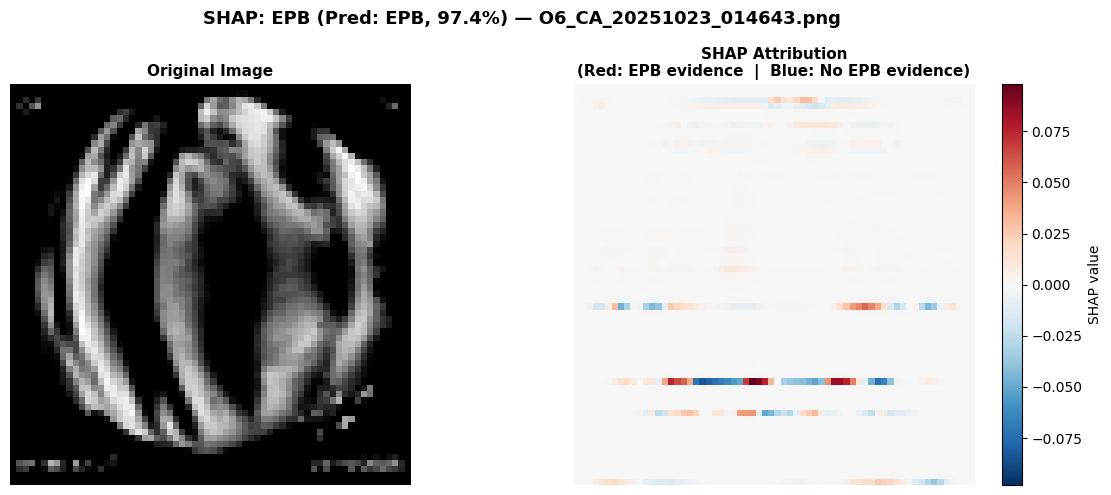


🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_BJL_20250723_073805.png
   • True class: No EPB
   • Prediction: No EPB (2.5%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 33.4% (↓ No EPB)
   • Upper Right: 31.7% (↓ No EPB)
   • Lower Left: 17.5% (↓ No EPB)
   • Lower Right: 17.4% (↓ No EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: 0.225 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões azuis no mapa SHAP mostram evidência de ionosfera
   quieta (ausência de estruturas irregulares).


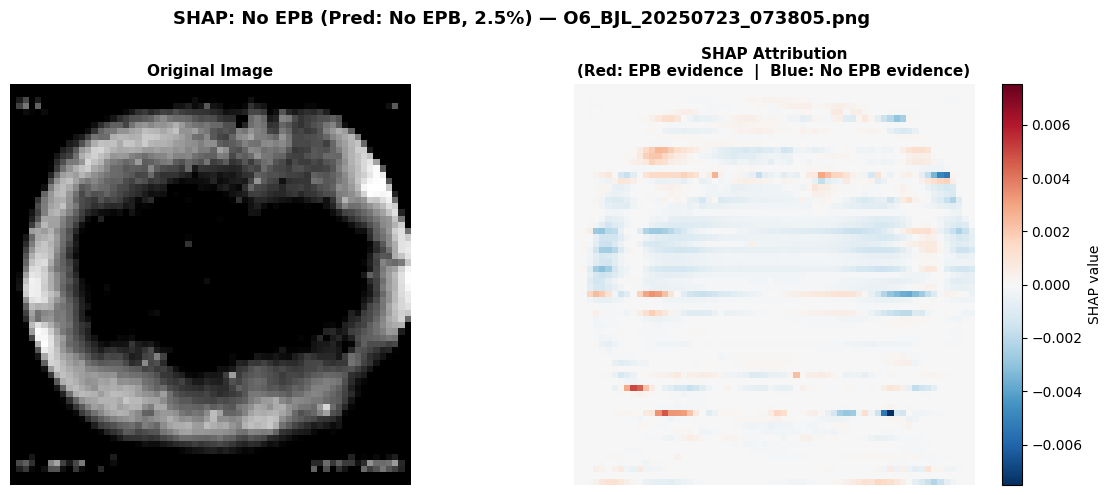


⚠️  ANÁLISE SHAP DE ERRO DE CLASSIFICAÇÃO:

🔬 ANÁLISE SHAP — Importance Real para Classificação

📸 Imagem: O6_CA_20251219_021243.png
   • True class: EPB
   • Prediction: No EPB (24.0%)
   • Método SHAP: TreeExplainer (tree-based)

📊 SHAP contribution by quadrant:
   • Upper Left: 40.6% (↓ No EPB)
   • Upper Right: 36.6% (↓ No EPB)
   • Lower Right: 13.4% (↑ EPB)
   • Lower Left: 9.5% (↑ EPB)

📐 Correlação |SHAP| vs. Reconstruction Error: -0.019 (Spearman)
   → Baixa correlação: SHAP e reconstrução focam em regiões distintas

💡 Interpretation:
   As regiões azuis no mapa SHAP mostram evidência de ionosfera
   quieta (ausência de estruturas irregulares).


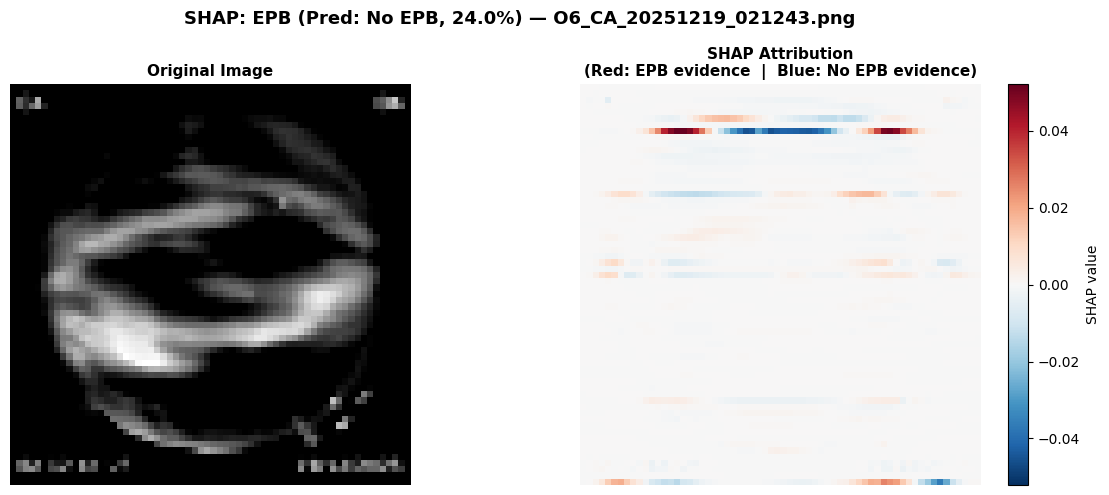

In [13]:
# ========== ETAPA 6b: ANÁLISE SHAP — IMPORTÂNCIA REAL ==========
# O mapa SHAP mostra quais regiões da imagem realmente influenciam
# a decisão do classificador (não apenas o erro de reconstrução 2DPCA).
# Vermelho = evidência a favor de EPB | Azul = evidência contra EPB

print("="*70)
print("ETAPA 6b: ANÁLISE SHAP — IMPORTÂNCIA REAL PARA CLASSIFICAÇÃO")
print("="*70)

# Exemplo 1: EPB corretamente classificado
epb_correct_idx = np.where((y_test == 1) & (y_pred == 1))[0]
if len(epb_correct_idx) > 0:
    idx = epb_correct_idx[0]
    explain_shap_importance(
        system, X_test[idx], y_test[idx], X_train,
        filename=files_test[idx], method='tree',
    )

# Exemplo 2: Sem EPB corretamente classificado
no_epb_correct_idx = np.where((y_test == 0) & (y_pred == 0))[0]
if len(no_epb_correct_idx) > 0:
    idx = no_epb_correct_idx[0]
    explain_shap_importance(
        system, X_test[idx], y_test[idx], X_train,
        filename=files_test[idx], method='tree',
    )

# Exemplo 3: Erro de classificação (se existir)
errors_idx = np.where(y_test != y_pred)[0]
if len(errors_idx) > 0:
    idx = errors_idx[0]
    print(f"\n⚠️  ANÁLISE SHAP DE ERRO DE CLASSIFICAÇÃO:")
    explain_shap_importance(
        system, X_test[idx], y_test[idx], X_train,
        filename=files_test[idx], method='tree',
    )

In [14]:
# ========== ETAPA 7: SALVAMENTO DO MODELO ==========
from epb_detection_system import EPBModelData, save_model

print("="*70)
print("ETAPA 7: SALVAMENTO DO MODELO")
print("="*70)

model_data = EPBModelData(
    version=MODEL_VERSION,
    system=system,
    n_components=N_COMPONENTS,
    target_size=TARGET_SIZE,
    test_metrics={
        'accuracy': float(np.mean(y_pred == y_test)),
        'sensitivity': float(sensitivity),
        'specificity': float(specificity),
        'ppv': float(ppv),
        'npv': float(npv),
    }
)

file_hash = save_model(model_data, f'models/epb_recognition_model-v{MODEL_VERSION}.pkl')

print(f"   ✓ Modelo salvo: models/epb_recognition_model-v{MODEL_VERSION}.pkl (v{MODEL_VERSION})")
print(f"   ✓ SHA-256: {file_hash[:16]}...")

print("\n" + "="*70)
print("✅ PIPELINE COMPLETO EXECUTADO COM SUCESSO!")
print("="*70)

ETAPA 7: SALVAMENTO DO MODELO


INFO: Modelo salvo: models/epb_recognition_model-v3.0.pkl (SHA-256: 8d0045fa4ae253e8...)


   ✓ Modelo salvo: models/epb_recognition_model-v3.0.pkl (v3.0)
   ✓ SHA-256: 8d0045fa4ae253e8...

✅ PIPELINE COMPLETO EXECUTADO COM SUCESSO!


## 📊 EXPLICAÇÃO DETALHADA DA VISUALIZAÇÃO GERADA

O dashboard de análise é dividido em **5 LINHAS**, cada uma com múltiplos gráficos:

---

### 📍 **LINHA 1: Exemplos de Classificação (6 imagens)**

**O que mostra:** 6 imagens de teste aleatórias com suas predições

**Elementos:**
- **Imagem:** Visualização da imagem EPB processada (colormap plasma)
- **Título verde:** Classificação CORRETA (predição = realidade)
- **Título vermelho:** Classificação INCORRETA (erro do modelo)
- **Informações:** 
  - `Real:` Classe verdadeira (EPB ou Sem EPB)
  - `Pred:` Classe predita pelo modelo
  - `(X%)` Probabilidade/confiança da predição

**Interpretação:** Permite visualizar rapidamente acertos e erros do modelo em casos reais.

---

### 📍 **LINHA 2: Análise de Features e Performance**

#### **Gráfico 1 (esquerda): Variância por Componente 2DPCA**
- **Eixo X:** Índice do componente (0, 1, 2, ...)
- **Eixo Y:** Variância explicada por cada componente
- **Barras azuis:** Quanto cada componente contribui para representar os dados
- **Interpretação:** Primeiros componentes capturam mais informação (barras maiores). Componentes finais capturam menos (podem ser ruído).

#### **Gráfico 2 (centro-esquerda): Variância Cumulativa**
- **Linha azul:** Soma acumulada da variância explicada
- **Linha vermelha tracejada:** 90% da variância
- **Linha laranja tracejada:** 95% da variância
- **Interpretação:** Mostra quantos componentes são necessários para capturar X% da informação. Ex: "Com 15 componentes, capturamos 92% da variância total".

#### **Gráfico 3 (direita): Matriz de Confusão**
- **Linhas:** Classe real (verdade)
- **Colunas:** Classe predita (modelo)
- **Células:**
  - **Superior esquerda (azul escuro):** Verdadeiros Negativos (VN) - Sem EPB, predito corretamente
  - **Inferior direita (azul escuro):** Verdadeiros Positivos (VP) - EPB, predito corretamente
  - **Superior direita:** Falsos Positivos (FP) - Predisse EPB, mas não tinha
  - **Inferior esquerda:** Falsos Negativos (FN) - Tinha EPB, mas não detectou
- **Interpretação:** Diagonal principal (azul escuro) = acertos. Fora da diagonal = erros.

---

### 📍 **LINHA 3: Métricas de Discriminação**

#### **Gráfico 1 (esquerda): Curva ROC**
- **Linha laranja:** Performance do modelo
- **Linha azul tracejada:** Classificador aleatório (50% de chance)
- **AUC (Area Under Curve):** Área sob a curva (quanto mais próximo de 1.0, melhor)
- **Eixo X:** Taxa de Falsos Positivos (FPR)
- **Eixo Y:** Taxa de Verdadeiros Positivos (TPR/Recall)
- **Interpretação:** 
  - AUC = 1.0: Modelo perfeito
  - AUC = 0.9-0.99: Excelente
  - AUC = 0.8-0.89: Bom
  - AUC = 0.5: Igual a sorte

#### **Gráfico 2 (centro): Curva Precision-Recall**
- **Linha roxa:** Trade-off entre precisão e recall
- **Eixo X:** Recall (sensibilidade - detecta EPBs reais)
- **Eixo Y:** Precision (confiança - evita falsos alarmes)
- **Interpretação:** Quanto mais próximo do canto superior direito, melhor o equilíbrio entre detectar EPBs e evitar falsos alarmes.

#### **Gráfico 3 (direita): Distribuição de Probabilidades**
- **Histograma azul:** Imagens SEM EPB - distribuição das probabilidades preditas
- **Histograma vermelho:** Imagens COM EPB - distribuição das probabilidades preditas
- **Linha verde vertical:** Threshold de decisão (0.5)
- **Interpretação:** 
  - Boa separação: histogramas bem separados (azul à esquerda, vermelho à direita)
  - Má separação: histogramas sobrepostos (modelo confuso)
  - À esquerda do threshold: predito como "Sem EPB"
  - À direita do threshold: predito como "EPB"

---

### 📍 **LINHA 4: Interpretação de Features (2 exemplos)**

Para cada classe (EPB e Sem EPB), mostra 3 imagens:

#### **Sequência 1: Exemplo de EPB**
1. **Original:** Imagem EPB real como foi capturada
2. **Mapa de Importância (hot colormap):**
   - **Vermelho/Amarelo:** Regiões mais importantes para classificação
   - **Azul/Preto:** Regiões menos relevantes
   - Mostra onde o modelo "olha" para decidir
3. **Reconstruído:** Imagem reconstruída pelos componentes 2DPCA
   - Compara com original para ver o que foi preservado/perdido

#### **Sequência 2: Exemplo de Sem EPB**
- Mesma estrutura acima, mas para uma imagem sem EPB
- Permite comparar quais regiões são importantes em cada classe

**Interpretação:** Valida se o modelo está focando em regiões fisicamente plausíveis para EPBs (estruturas verticais, deplecções de plasma).

---

### 📍 **LINHA 5: Componentes Principais Visualizados (6 componentes)**

**O que mostra:** Visualização dos primeiros 6 componentes principais do 2DPCA

**Cada subplot:**
- **Imagem:** Representação visual do componente (como um "filtro")
- **Título:** `Comp X (Y%)`
  - `X`: Índice do componente (1, 2, 3, ...)
  - `Y%`: Percentual de variância explicada por esse componente
- **Colormap RdBu_r:** 
  - Vermelho: valores positivos
  - Azul: valores negativos
  - Branco: valores próximos de zero

**Interpretação:** 
- Primeiros componentes (alta % variância): capturam padrões gerais, estrutura principal
- Componentes posteriores (baixa % variância): capturam detalhes finos, ruído
- Padrões verticais/horizontais: podem indicar características espaciais dos EPBs

---

## 🎯 **COMO INTERPRETAR O SISTEMA COMPLETO**

### ✅ **Sistema BOM:**
- Matriz de confusão: Diagonal forte (muitos VP e VN)
- ROC AUC: > 0.90
- Distribuição de probabilidades: Bem separada
- Mapa de importância: Foca em regiões plausíveis

### ⚠️ **Sistema PRECISA MELHORAR:**
- Matriz de confusão: Muitos FP ou FN
- ROC AUC: < 0.80
- Distribuição de probabilidades: Muito sobreposta
- Mapa de importância: Foca em regiões aleatórias/bordas

### 📌 **Métricas Críticas para EPBs:**
- **Sensitivity (Recall):** Alta → Detecta a maioria dos EPBs reais (evita perder eventos)
- **Specificity:** Alta → Evita falsos alarmes (não confunde ionosfera quieta com EPB)
- **Equilíbrio:** Ambos devem ser > 85% para aplicação científica confiável

## 🕐 Análise Temporal de Sequência de Imagens

Esta seção permite analisar como a probabilidade de EPB evolui ao longo de uma noite de observação.

**Funcionalidades:**
- Processa todas as imagens de uma pasta em ordem cronológica
- Gera gráfico de evolução da probabilidade ao longo do tempo
- Identifica transições (mudanças de estado EPB ↔ Sem EPB)
- Mostra thumbnails das imagens para validação visual
- Gera heatmap temporal para visualização compacta

**Uso científico:**
- Verificar se o modelo detecta EPBs **antes** de serem visíveis
- Identificar precursores de EPBs
- Analisar a dinâmica temporal de eventos ionosféricos